# Configuration

In [1]:
import os
import torch
from IPython.display import display
import matplotlib.pyplot as plt

from pipelines.pipeline_ctag_stablediffusionXL import StableDiffusionXL_CTAGPipeline

prompt_path = os.path.join(os.getcwd(), "cute_animal.txt")
cfg = 5.
seed = 12
device = "cuda"
dtype = torch.float16

height = 512
width = 512
latent_shape = (1, 4, 128, 128)  # latent size for SDXL at 512x512

t_guidance_rescale = 2.5  # eta in Eq. (26); matches the demo's previous effective strength (0.5 * cfg 5)
start_tag_at       = 1000 
end_tag_at         = 800

## Utilities 

In [2]:
def load_txt(file_path):
    with open(file_path, "r", encoding="utf-8") as f:
        return [line.strip() for line in f if line.strip()]

def make_latent(seed, shape=latent_shape, device=device, dtype=dtype):
    g = torch.Generator(device=device).manual_seed(seed)
    return torch.randn(shape, device=device, dtype=dtype, generator=g)

def show_side_by_side(img_a, img_b, title_a="CTAG", title_b="SDXL Pure", suptitle=None):
    plt.figure(figsize=(8, 4))
    if suptitle:
        plt.suptitle(suptitle, fontsize=12)

    plt.subplot(1, 2, 1)
    plt.imshow(img_a)
    plt.axis("off")
    plt.title(title_a)

    plt.subplot(1, 2, 2)
    plt.imshow(img_b)
    plt.axis("off")
    plt.title(title_b)

    plt.tight_layout()
    plt.show()

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

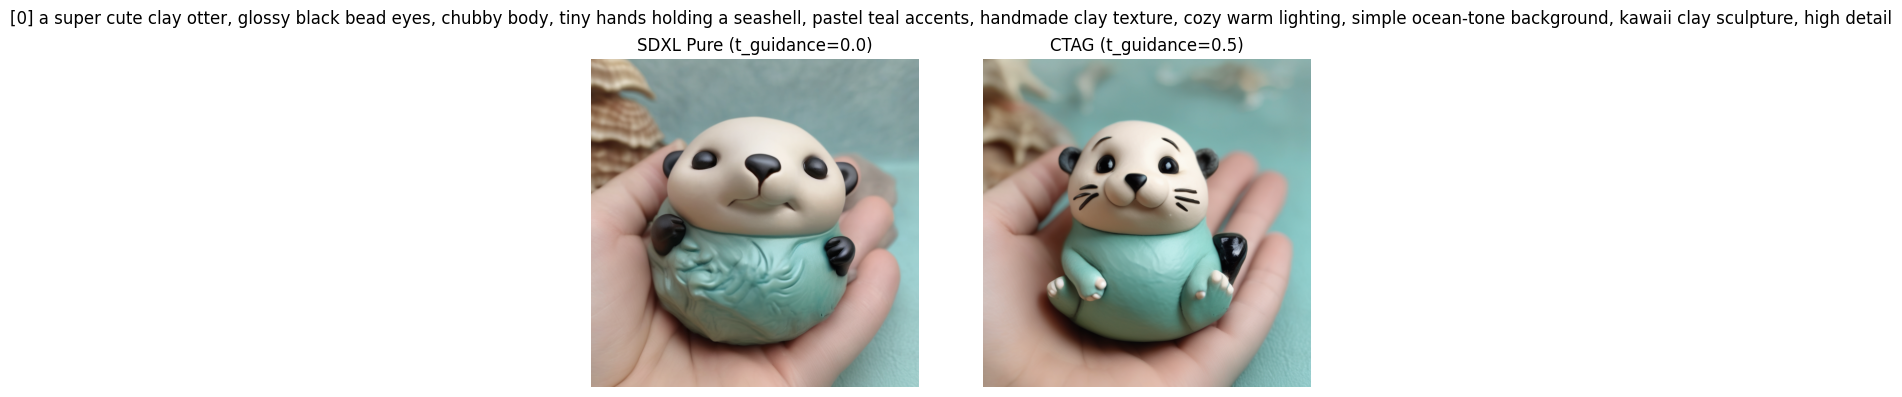

In [3]:
pipeline = StableDiffusionXL_CTAGPipeline.from_pretrained(
    "stabilityai/stable-diffusion-xl-base-1.0",
    torch_dtype=dtype,
    variant="fp16",
    use_safetensors=True,
).to(device)

pipeline.safety_checker = None 

prompt_ls = load_txt(prompt_path)

for idx, prompt in enumerate(prompt_ls):
    latent = make_latent(seed)

    tag_image = pipeline(
        prompt=prompt,
        height=height,
        width=width,
        latents=latent,
        guidance_scale=cfg,
        t_guidance_scale=t_guidance_rescale,
        sta_tpd=start_tag_at,
        end_tpd=end_tag_at,
    ).images[0]

    sdxl_image = pipeline(
        prompt=prompt,
        height=height,
        width=width,
        latents=latent,
        guidance_scale=cfg,
        t_guidance_scale=0.0,
    ).images[0]

    show_side_by_side(
        sdxl_image,
        tag_image,
        title_a="SDXL Pure (t_guidance=0.0)",
        title_b=f"CTAG (t_guidance={t_guidance_rescale})",
        suptitle=f"[{idx}] {prompt}"
    )
